# 05 – Candidate hanging glaciers of the massif and geometric ranking

Input: `hanging_probability_revised_10m.tif` (notebook 04, forest trained on the revised labels of the 4 blocks).

1. Connected glacier pixels with probability ≥ 0.5 and at least 1 ha form a **candidate** (`src/candidates.py`).
2. Each candidate is described by its area, the mean slope of its surface and its **fall height** (90th percentile
   of the height of the step below the lower edge, from `src/downslope.py`).
3. **Geometric index** = mean of the percentile ranks of these three variables (0 = lowest of the massif,
   1 = highest). It is a relative ranking, fixed before looking at the results, not a calibrated hazard score.

The thermal state of the candidates (cold or temperate base) is not assessed: it needs measurements on each glacier.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize

import candidates as cd
from classifier import load_grids
from config import CRS, DEM_RES, PROCESSED, RAW
from relief import hillshade

FIG = ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

F, names, labels, profile = load_grids()
transform = profile["transform"]
layers = dict(zip(names, F))
layers["glacier"] = labels["glacier"]
with rasterio.open(PROCESSED / f"hanging_probability_revised_{DEM_RES}m.tif") as src:
    prob = src.read(1)
glaciers = gpd.read_file(PROCESSED / "sgi2023_zone.gpkg", layer="glaciers")
polygons = gpd.read_file(RAW / "manual_mapping.gpkg", layer="hanging_glaciers")
polygons_grid = rasterize(((g, 1) for g in polygons.make_valid()), out_shape=prob.shape, transform=transform, fill=0)

## 1. Candidates

In [2]:
cand, n = cd.label_candidates(np.nan_to_num(prob), DEM_RES)
table = cd.describe(cand, n, DEM_RES, prob, layers, glaciers, polygons_grid, labels["block"])
outlines = cd.polygons_of(cand, transform, CRS).merge(table, on="candidate_id")
outlines.to_file(PROCESSED / "candidates.gpkg", layer="candidates", driver="GPKG")

new = ~table["in_block"]
print(f"{n} candidates (≥ {cd.MIN_AREA_HA} ha, probability ≥ {cd.THRESHOLD}), {table['area_ha'].sum():.0f} ha in total")
print(f"  {new.sum()} outside the mapping blocks ({table.loc[new, 'area_ha'].sum():.0f} ha), "
      f"{(~new).sum()} inside them")
print(f"  {(table['glacier_area_km2'] > 1).sum()} lie within a glacier larger than 1 km² "
      f"(hanging parts of large outlines), {(table['glacier_area_km2'] <= 1).sum()} are or lie within small units")
print(table[INDEX := cd.INDEX_VARIABLES].describe().round(1).loc[["min", "50%", "max"]])

/home/alexg/miniforge3/envs/icefal/lib/python3.11/site-packages/rasterio/features.py:129: RuntimeWarning: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.
  yield from _shapes(source, mask, connectivity, transform)


151 candidates (≥ 1 ha, probability ≥ 0.5), 861 ha in total
  110 outside the mapping blocks (478 ha), 41 inside them
  105 lie within a glacier larger than 1 km² (hanging parts of large outlines), 46 are or lie within small units
     area_ha  slope_mean  fall_height
min      1.0        12.1         61.0
50%      3.3        34.6        123.0
max     38.3        51.0        284.0


## 2. Ranking

The 20 candidates with the highest geometric index. `mapped_share` is the part of the candidate covered by the
manual mapping (0 for candidates found only by the model, outside the blocks or missed there).

In [3]:
cols = ["rank", "candidate_id", "glacier", "sgi_id", "area_ha", "slope_mean", "fall_height", "z_min", "z_max",
        "northness", "mean_prob", "in_block", "mapped_share", "geometric_index"]
top = table.sort_values("rank")[cols].head(20)
top.to_csv(ROOT / "report" / "top20_candidates.csv", index=False)
top

,rank,candidate_id,glacier,sgi_id,area_ha,slope_mean,fall_height,z_min,z_max,northness,mean_prob,in_block,mapped_share,geometric_index
146,1,147,Zmuttgletscher,B57-05,34.2,43.7,142.0,3240.0,4027.0,0.90,0.93,False,0.00,0.898
97,2,98,Glacier de Zinal,B63-05,5.5,51.0,176.0,3726.0,4074.0,1.00,0.99,True,0.98,0.868
57,3,58,Glacier de Moming,B62-10,17.7,41.5,140.0,3410.0,3995.0,0.84,0.83,False,0.00,0.859
90,4,91,Glacier de Zinal,B63-05,11.1,40.4,159.0,3517.0,3894.0,0.31,0.85,False,0.00,0.845
93,5,94,Glacier de Zinal,B63-05,20.6,37.4,166.0,3121.0,3668.0,0.72,0.93,True,0.85,0.828
48,6,49,Kingletscher,B55-08,21.3,41.6,130.0,3820.0,4459.0,0.59,0.96,True,0.95,0.821
35,7,36,Hohbalmgletscher,B53-07,4.0,49.3,153.0,3882.0,4278.0,0.88,0.88,False,0.00,0.801
54,7,55,Glacier de Moming,B62-10,7.7,40.5,143.0,3226.0,3599.0,0.75,0.90,True,0.64,0.801
36,9,37,Bisgletscher,B58-08,38.3,45.5,118.0,3790.0,4489.0,0.64,0.95,True,0.83,0.795
45,10,46,Festigletscher,B55-07,2.9,45.3,185.0,4156.0,4375.0,0.30,0.74,False,0.00,0.767


**Robustness of the ranking.** The index weights its three variables equally. The rank correlation (Spearman)
between the full index and the index with one variable left out shows how much the ranking depends on each one.

In [4]:
ranks = table[cd.INDEX_VARIABLES].rank(pct=True)
for left_out in cd.INDEX_VARIABLES:
    partial = ranks.drop(columns=left_out).mean(axis=1)
    rho = table["geometric_index"].corr(partial, method="spearman")
    top20 = set(table.nlargest(20, "geometric_index")["candidate_id"])
    top20_partial = set(table.loc[partial.nlargest(20).index, "candidate_id"])
    print(f"without {left_out:>12}: Spearman {rho:.2f}, {len(top20 & top20_partial)} of the top 20 unchanged")

without      area_ha: Spearman 0.83, 12 of the top 20 unchanged
without   slope_mean: Spearman 0.82, 9 of the top 20 unchanged
without  fall_height: Spearman 0.81, 16 of the top 20 unchanged


## 3. Map

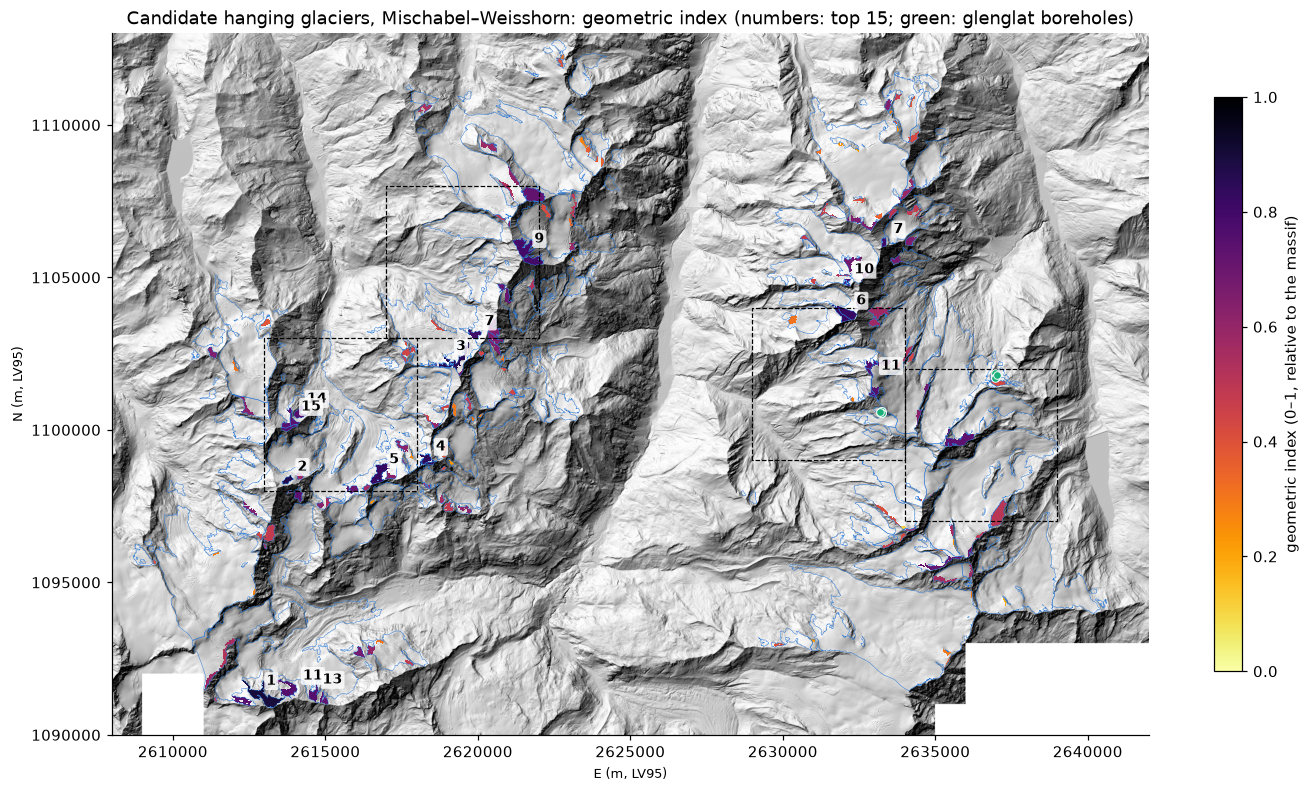

In [5]:
with rasterio.open(PROCESSED / f"dem_{DEM_RES}m.tif") as src:
    dem = src.read(1)
shade = hillshade(dem, DEM_RES)
blocks = gpd.read_file(RAW / "manual_mapping.gpkg", layer="blocks")
boreholes = pd.read_csv(RAW / "glenglat" / "data" / "borehole.csv")
boreholes = boreholes[boreholes["glacier_name"].isin(["Alphubel South", "Chessjengletscher"])]
boreholes = gpd.GeoDataFrame(boreholes, geometry=gpd.points_from_xy(boreholes["longitude"], boreholes["latitude"]),
                             crs=4326).to_crs(CRS)
x0, y0 = transform * (0, dem.shape[0])
x1, y1 = transform * (dem.shape[1], 0)

fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(shade, cmap="gray", extent=(x0, x1, y0, y1), vmin=-0.2, vmax=1)
glaciers.boundary.plot(ax=ax, color="#2a78d6", lw=0.3)
blocks.boundary.plot(ax=ax, color="black", lw=0.8, ls="--")
outlines.plot(ax=ax, column="geometric_index", cmap="inferno_r", vmin=0, vmax=1, legend=True,
              legend_kwds={"shrink": 0.6, "label": "geometric index (0–1, relative to the massif)"})
boreholes.plot(ax=ax, color="#1baf7a", markersize=25, edgecolor="white", linewidth=0.6, zorder=5)
for _, c in outlines.nsmallest(15, "rank").iterrows():
    p = c.geometry.representative_point()
    ax.annotate(str(c["rank"]), (p.x, p.y), xytext=(6, 6), textcoords="offset points", fontsize=9,
                fontweight="bold", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
ax.set_title("Candidate hanging glaciers, Mischabel–Weisshorn: geometric index (numbers: top 15; green: glenglat boreholes)")
ax.ticklabel_format(style="plain")
ax.set_xlabel("E (m, LV95)"); ax.set_ylabel("N (m, LV95)")
fig.tight_layout()
fig.savefig(FIG / "05_candidates_map.png", dpi=150)

## 4. Borehole sites

The only englacial temperature measurements of the area are the glenglat boreholes of Beer et al. (2026) on
Alphubel and Chessjengletscher. Are they on or near a candidate?

In [6]:
for name, grp in boreholes.groupby("glacier_name"):
    d = outlines.distance(grp.geometry.union_all())
    c = outlines.loc[d.idxmin()]
    print(f"{name}: nearest candidate {c['candidate_id']} ({c['glacier']}, rank {c['rank']} of {n}) "
          f"at {d.min():.0f} m; boreholes at {grp['elevation'].min():.0f}–{grp['elevation'].max():.0f} m")

Alphubel South: nearest candidate 64 (Feegletscher, rank 11 of 151) at 442 m; boreholes at 3759–3820 m
Chessjengletscher: nearest candidate 70 (Chessjengletscher NW, rank 99 of 151) at 114 m; boreholes at 2983–3046 m


## 5. Check of the candidates on the imagery

The author judged candidates on SWISSIMAGE with the mapping rules (`data/raw/candidates_review.gpkg`, layer
`to_check`, built by `src/prepare_candidate_review.py`): the top 20, the candidates touching a block but not
mapped, and a **random sample of 25 candidates outside the blocks** (fixed seed). Nothing was added to the labels.

Only the random sample estimates the precision of the model outside its training area: the top 20 are the
easiest cases. Candidates are judged while seeing the model's outline, which favours agreement, so the
estimate is optimistic. 95 % interval: Wilson score interval.

In [7]:
review = gpd.read_file(RAW / "candidates_review.gpkg", layer="to_check")
print(pd.crosstab(review["reason"], review["verdict"].fillna("not judged"), margins=True))


def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


for label, sub in [("top 20, outside the blocks", review[(review["reason"] == "top 20") & ~review["in_block"]]),
                   ("random sample outside the blocks", review[review["reason"] == "random sample"])]:
    judged = sub[sub["verdict"].notna()]
    k, n = (judged["verdict"] == "hanging").sum(), len(judged)
    lo, hi = wilson(k, n)
    k_u = judged["verdict"].isin(["hanging", "unsure"]).sum()
    print(f"{label}: {k} of {n} judged hanging, precision {k / n:.2f} (95 % interval {lo:.2f}–{hi:.2f}); "
          f"{k_u / n:.2f} if unsure counts as hanging; {len(sub) - n} not judged")

verdict                 hanging  not_hanging  unsure  All
reason                                                   
in a block, not mapped        2            0       4    6
random sample                19            5       1   25
top 20                       19            0       1   20
All                          40            5       6   51
top 20, outside the blocks: 8 of 9 judged hanging, precision 0.89 (95 % interval 0.56–0.98); 1.00 if unsure counts as hanging; 0 not judged
random sample outside the blocks: 19 of 25 judged hanging, precision 0.76 (95 % interval 0.57–0.89); 0.80 if unsure counts as hanging; 0 not judged
